**Colab setup.** Unzips the project, moves into its folder and installs two extra packages. Expected output: the folder path and no errors.

In [1]:
!unzip -q -o /content/plant-disease-mlops.zip -d /content
%cd /content/plant-disease-mlops
!pip install -q kagglehub seaborn

/content/plant-disease-mlops


# Plant Leaf Disease Classification - ML pipeline
Image classification of 15 leaf conditions (PlantVillage: pepper, potato, tomato) with transfer learning (MobileNetV2).
This notebook covers **data acquisition, preprocessing, visualisation, model training, evaluation and prediction**.
The same code lives in `src/` and is used by the API, UI and retraining.

**Setup.** Import libraries and project settings. Expected output: the TensorFlow version and the data/model folders.

In [2]:
import os, sys, json, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, keras

# make `src/` importable whether the notebook runs from notebook/ or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config
from src.data_acquisition import download_plantvillage, find_class_root, split_and_copy
from src.preprocessing import (build_datasets, class_distribution, compute_class_weights,
                               compute_image_features, prepare_image)
from src.model import (build_model, compile_model, unfreeze_top, default_callbacks,
                       evaluate_model, predict_probs, save_model)

random.seed(config.SEED); np.random.seed(config.SEED); tf.random.set_seed(config.SEED)
HEAD_EPOCHS = int(os.getenv("HEAD_EPOCHS", 8))          # phase 1: train the new head
FINETUNE_EPOCHS = int(os.getenv("FINETUNE_EPOCHS", 10)) # phase 2: fine-tune the top of MobileNetV2
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("Train dir:", config.TRAIN_DIR); print("Models dir:", config.MODELS_DIR)

TensorFlow 2.21.0 | Keras 3.13.2
Train dir: /content/plant-disease-mlops/data/train
Models dir: /content/plant-disease-mlops/models


## 1. Data acquisition

**Download and split the data.** Downloads PlantVillage from Kaggle and makes a stratified 80/20 train/test split. Skipped if `data/train` already has images. Expected output: images per class for train and test.

In [3]:
if not any(config.TRAIN_DIR.glob("*/*")):
    src_root = find_class_root(download_plantvillage())
    split_and_copy(src_root, max_per_class=int(os.getenv("MAX_PER_CLASS", 0)) or None)
else:
    print("Data already prepared - skipping download.")
summary = pd.DataFrame({"train": class_distribution(config.TRAIN_DIR), "test": class_distribution(config.TEST_DIR)})
summary.loc["TOTAL"] = summary.sum()
summary

Using Colab cache for faster access to the 'plantdisease' dataset.


,train,test
Pepper__bell___Bacterial_spot,798,199
Pepper__bell___healthy,1183,295
Potato___Early_blight,800,200
Potato___Late_blight,800,200
Potato___healthy,122,30
Tomato_Bacterial_spot,1702,425
Tomato_Early_blight,800,200
Tomato_Late_blight,1528,381
Tomato_Leaf_Mold,762,190
Tomato_Septoria_leaf_spot,1417,354


## 2. Data exploration and visualisation

**Class distribution.** Shows how many training images each class has. Expected output: a horizontal bar chart.

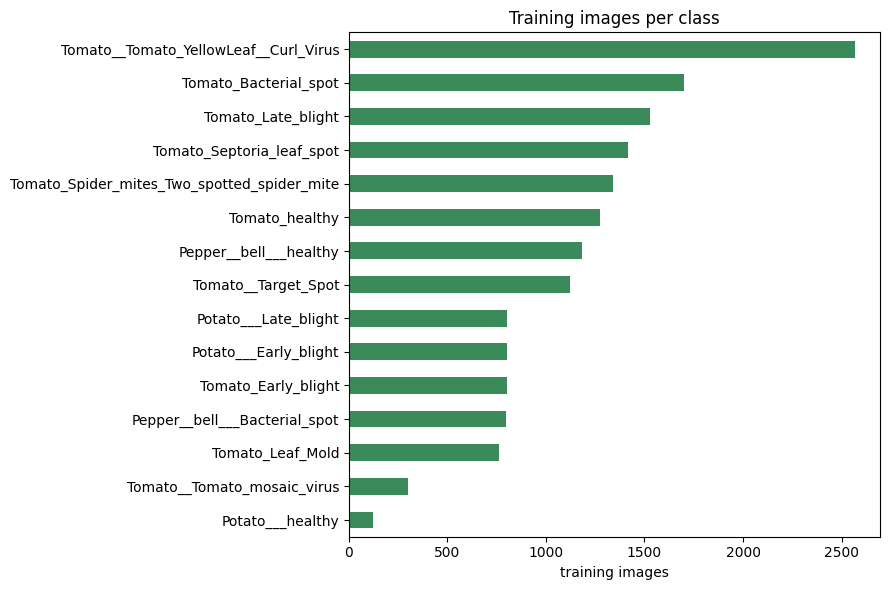

Largest / smallest class ratio: 21.0x


In [4]:
dist = class_distribution(config.TRAIN_DIR).sort_values()
ax = dist.plot.barh(figsize=(9, 6), color="#3b8b5a")
ax.set_xlabel("training images"); ax.set_title("Training images per class")
plt.tight_layout(); plt.show()
print(f"Largest / smallest class ratio: {dist.max() / dist.min():.1f}x")

**Interpretation 1 - class balance.**
The classes are clearly imbalanced. Tomato Yellow Leaf Curl Virus has the most training images (2,567) and healthy potato the fewest (122), a 21x difference. Tomato mosaic virus (299) is also small.
Without a correction the model could favour the big classes, so I used **class weights** (from 0.43 for the largest class up to 9.03 for healthy potato) and I report **macro** precision, recall and F1, not accuracy alone.

**Sample images.** One random leaf per class. Expected output: a grid of leaf photos with class names.

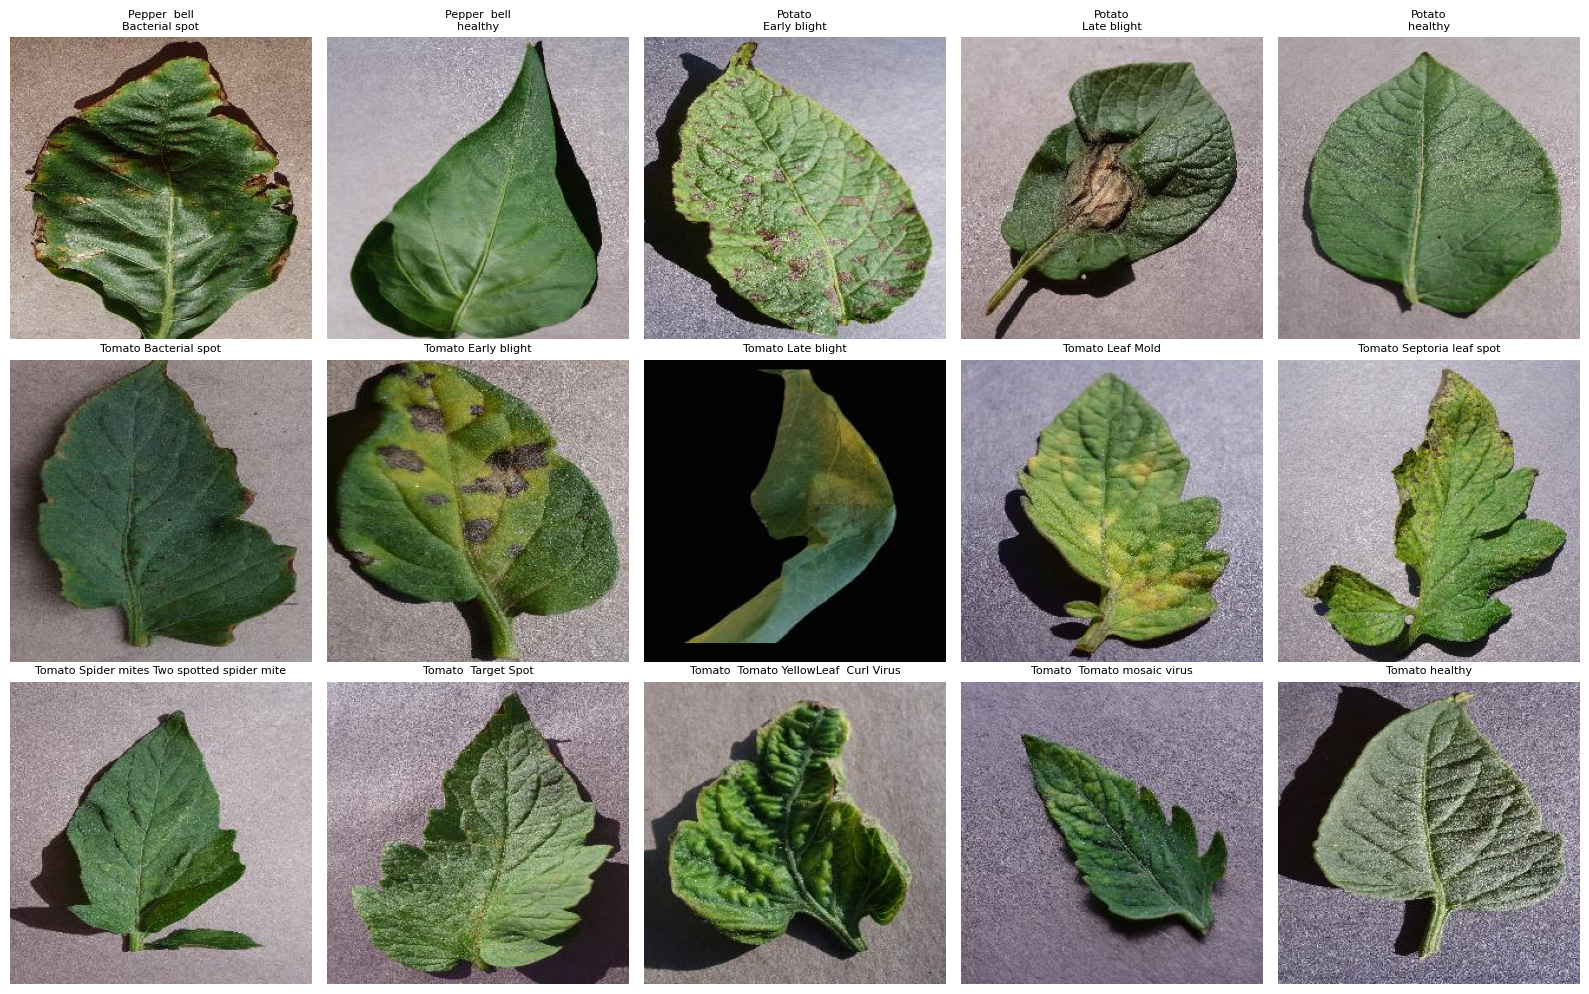

In [5]:
from PIL import Image
classes = sorted(p.name for p in config.TRAIN_DIR.iterdir() if p.is_dir())
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for ax, c in zip(axes.ravel(), classes):
    f = random.choice(list((config.TRAIN_DIR / c).iterdir()))
    ax.imshow(Image.open(f)); ax.set_title(c.replace("___", "\n").replace("_", " "), fontsize=8); ax.axis("off")
for ax in axes.ravel()[len(classes):]: ax.axis("off")
plt.tight_layout(); plt.show()

**Colour features.** For a sample of images per class we measure average green, brightness and share of non-green pixels. Expected output: a table of average values per class.

In [6]:
feats = compute_image_features(config.TRAIN_DIR, per_class=80)
feats.groupby("class")[["mean_green", "brightness", "non_green_ratio"]].mean().round(2)

,mean_green,brightness,non_green_ratio
class,,,
Pepper__bell___Bacterial_spot,124.269997,115.540001,0.55
Pepper__bell___healthy,137.979996,126.370003,0.47
Potato___Early_blight,141.330002,131.300003,0.56
Potato___Late_blight,118.430000,113.459999,0.63
Potato___healthy,133.050003,123.790001,0.50
Tomato_Bacterial_spot,108.519997,101.279999,0.50
Tomato_Early_blight,109.580002,104.599998,0.64
Tomato_Late_blight,115.339996,111.279999,0.73
Tomato_Leaf_Mold,115.930000,113.290001,0.68


**Feature plots.** Box plots of the three features for every class. Expected output: three charts, classes sorted by green level.

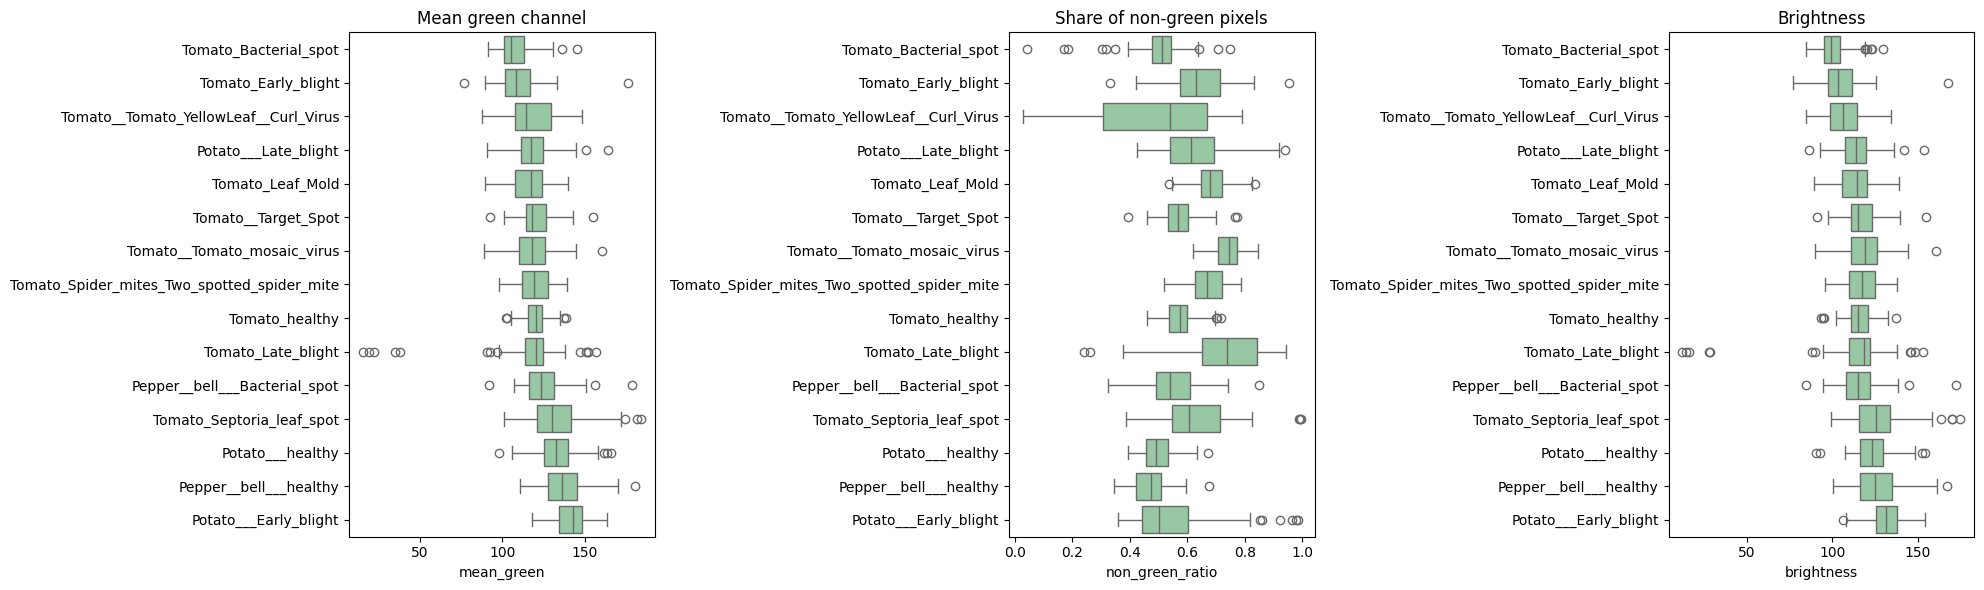

In [7]:
order = feats.groupby("class")["mean_green"].median().sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, col, title in zip(axes, ["mean_green", "non_green_ratio", "brightness"],
                          ["Mean green channel", "Share of non-green pixels", "Brightness"]):
    sns.boxplot(data=feats, y="class", x=col, order=order, ax=ax, color="#8fcf9f")
    ax.set_title(title); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretation 2 - three features.**

1. **Mean green:** the green level depends more on the crop, background and lighting than on health. In pepper, healthy leaves are greener (138 vs 124 for bacterial spot). In potato the pattern reverses: early blight (141) is greener than healthy (133). Diseased tomato classes sit both below and above healthy tomato (120). So colour alone cannot separate healthy from diseased leaves.
2. **Share of non-green pixels:** this is the most useful feature. Healthy pepper (0.47) and healthy potato (0.50) have the lowest values, while tomato mosaic virus (0.74), late blight (0.73) and leaf mold (0.68) have the highest, because damaged or discoloured tissue covers more of the leaf. Yellow Leaf Curl Virus has a very wide spread, so colour is unreliable for that class.
3. **Brightness:** the class averages range from about 101 (tomato bacterial spot) to 131 (potato early blight). Tomato late blight has a few very dark outliers (below 30), probably photos with a dark or black background, like one of the late blight test leaves. This lighting difference is why the model uses contrast augmentation.

**Overall story:** the colour features overlap heavily between classes, so the CNN has to learn texture and spot patterns. This fits the model's errors later, which are mostly between similar tomato spot diseases.

## 3. Data preprocessing

**Load datasets.** Images are resized to 224x224 and batched; 80% train / 20% validation from `data/train`, plus a separate test set. Pixel scaling to [-1, 1] happens inside the model. Expected output: image counts and class names.

In [8]:
train_ds, val_ds, test_ds, class_names = build_datasets()
print("Classes:", len(class_names))
x, y = next(iter(train_ds))
print("Batch shape:", x.shape, "| labels shape:", y.shape, "| pixel range:", float(tf.reduce_min(x)), "-", float(tf.reduce_max(x)))

Found 16516 files belonging to 15 classes.
Using 13213 files for training.
Found 16516 files belonging to 15 classes.
Using 3303 files for validation.
Found 4122 files belonging to 15 classes.
Classes: 15
Batch shape: (32, 224, 224, 3) | labels shape: (32, 15) | pixel range: 0.0 - 250.23423767089844


**Augmentation preview.** The model randomly flips, rotates, zooms and changes contrast during training only. Expected output: one leaf and 7 augmented versions.

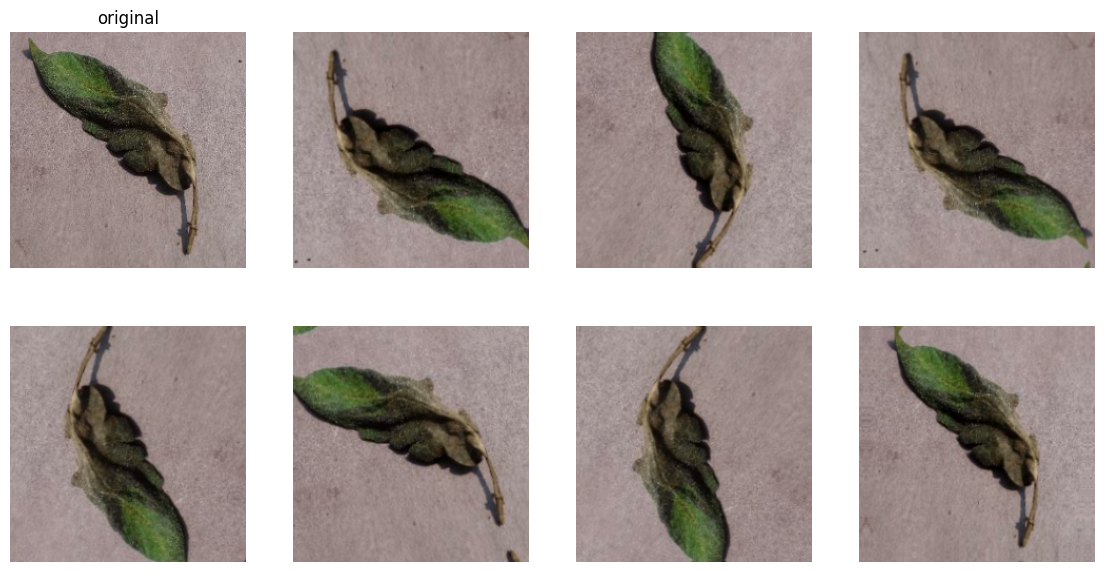

In [9]:
aug = keras.Sequential([keras.layers.RandomFlip("horizontal_and_vertical"), keras.layers.RandomRotation(0.1),
                        keras.layers.RandomZoom(0.1), keras.layers.RandomContrast(0.1)])
img = x[:1]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes[0, 0].imshow(img[0].numpy().astype("uint8")); axes[0, 0].set_title("original")
for ax in axes.ravel()[1:]:
    ax.imshow(aug(img, training=True)[0].numpy().astype("uint8"))
for ax in axes.ravel(): ax.axis("off")
plt.show()

**Class weights.** Rare classes get a larger weight so the loss does not ignore them. Expected output: weight per class.

In [10]:
class_weights = compute_class_weights(config.TRAIN_DIR, class_names)
pd.Series({class_names[i]: round(w, 2) for i, w in class_weights.items()}, name="weight")

,weight
Pepper__bell___Bacterial_spot,1.38
Pepper__bell___healthy,0.93
Potato___Early_blight,1.38
Potato___Late_blight,1.38
Potato___healthy,9.03
Tomato_Bacterial_spot,0.65
Tomato_Early_blight,1.38
Tomato_Late_blight,0.72
Tomato_Leaf_Mold,1.44
Tomato_Septoria_leaf_spot,0.78


## 4. Model creation

**Build the model.** MobileNetV2 pre-trained on ImageNet + pooling, dropout, a Dense layer with L2 regularisation and a softmax output. Expected output: the model summary.

In [11]:
model = build_model(len(class_names))
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "plant_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probs (Dense)                   │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,887 (9.25 MB)

 Trainable params: 165,903 (648.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Training

**Phase 1 - train the new head.** The pre-trained base is frozen. Adam (lr 1e-3), EarlyStopping and ReduceLROnPlateau are used. Expected output: epochs with improving validation accuracy.

In [12]:
compile_model(model, lr=1e-3)
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
                  class_weight=class_weights, callbacks=default_callbacks())

Epoch 1/8
413/413 ━━━━━━━━━━━━━━━━━━━━ 43s 80ms/step - accuracy: 0.5995 - loss: 1.2527 - precision: 0.8014 - recall: 0.4480 - val_accuracy: 0.7696 - val_loss: 0.7335 - val_precision: 0.8833 - val_recall: 0.6485 - learning_rate: 0.0010
Epoch 2/8
413/413 ━━━━━━━━━━━━━━━━━━━━ 35s 85ms/step - accuracy: 0.7447 - loss: 0.7664 - precision: 0.8279 - recall: 0.6579 - val_accuracy: 0.8047 - val_loss: 0.6216 - val_precision: 0.8771 - val_recall: 0.7327 - learning_rate: 0.0010
Epoch 3/8
413/413 ━━━━━━━━━━━━━━━━━━━━ 30s 73ms/step - accuracy: 0.7826 - loss: 0.6665 - precision: 0.8491 - recall: 0.7166 - val_accuracy: 0.8347 - val_loss: 0.5361 - val_precision: 0.8895 - val_recall: 0.7723 - learning_rate: 0.0010
Epoch 4/8
413/413 ━━━━━━━━━━━━━━━━━━━━ 35s 85ms/step - accuracy: 0.7983 - loss: 0.6133 - precision: 0.8561 - recall: 0.7428 - val_accuracy: 0.8350 - val_loss: 0.5323 - val_precision: 0.9008 - val_recall: 0.7584 - learning_rate: 0.0010
Epoch 5/8
413/413 ━━━━━━━━━━━━━━━━━━━━ 30s 73ms/step - accur

**Phase 2 - fine-tune.** The top 80 layers of MobileNetV2 are unfrozen and trained with a smaller learning rate (1e-4, reduced automatically when validation loss stalls). Early stopping keeps the best epoch. Expected output: validation accuracy rising to about 0.96.

In [13]:
unfreeze_top(model, 80)
compile_model(model, lr=1e-4)
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS,
                  class_weight=class_weights, callbacks=default_callbacks())

Epoch 1/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 52s 102ms/step - accuracy: 0.7807 - loss: 0.6813 - precision: 0.8435 - recall: 0.7295 - val_accuracy: 0.9071 - val_loss: 0.3343 - val_precision: 0.9236 - val_recall: 0.8895 - learning_rate: 1.0000e-04
Epoch 2/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 83s 108ms/step - accuracy: 0.8748 - loss: 0.3888 - precision: 0.8986 - recall: 0.8544 - val_accuracy: 0.8765 - val_loss: 0.4369 - val_precision: 0.8886 - val_recall: 0.8647 - learning_rate: 1.0000e-04
Epoch 3/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 40s 97ms/step - accuracy: 0.9396 - loss: 0.2041 - precision: 0.9498 - recall: 0.9318 - val_accuracy: 0.9155 - val_loss: 0.2899 - val_precision: 0.9227 - val_recall: 0.9101 - learning_rate: 3.0000e-05
Epoch 4/10
413/413 ━━━━━━━━━━━━━━━━━━━━ 40s 97ms/step - accuracy: 0.9527 - loss: 0.1736 - precision: 0.9591 - recall: 0.9478 - val_accuracy: 0.9500 - val_loss: 0.1907 - val_precision: 0.9566 - val_recall: 0.9476 - learning_rate: 3.0000e-05
Epoch 5/10
413/413 ━━━━━━━━━━━━━━━━━━━

**Learning curves.** Training vs validation loss and accuracy over all epochs. Expected output: two charts; a small gap means little overfitting.

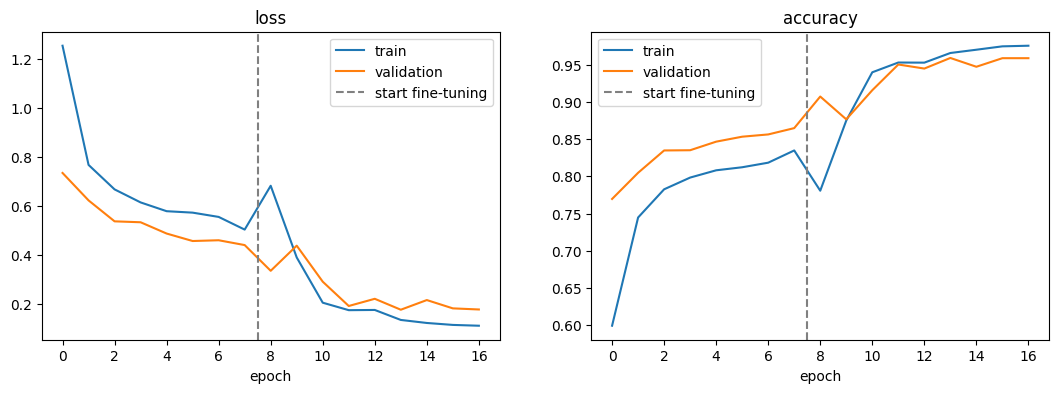

In [14]:
hist = {k: hist1.history[k] + hist2.history[k] for k in hist1.history}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["loss", "accuracy"]):
    ax.plot(hist[m], label="train"); ax.plot(hist["val_" + m], label="validation")
    ax.axvline(len(hist1.history["loss"]) - 0.5, color="grey", ls="--", label="start fine-tuning")
    ax.set_title(m); ax.set_xlabel("epoch"); ax.legend()
plt.show()

## 6. Model testing

**Test-set metrics.** The model is evaluated on images it never saw. Expected output: loss, accuracy, precision, recall and F1.

In [15]:
metrics = evaluate_model(model, test_ds, class_names)
pd.Series({k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)}, name="test").to_frame()

,test
loss,0.1621
accuracy,0.9624
precision_macro,0.9650
recall_macro,0.9671
f1_macro,0.9654
precision_weighted,0.9645
recall_weighted,0.9624
f1_weighted,0.9627


**Per-class report.** Precision, recall and F1 for each class. Expected output: a table; look for the weakest classes.

In [16]:
report = pd.DataFrame(metrics["report"]).T.round(3)
report.sort_values("f1-score").head(20)

,precision,recall,f1-score,support
Tomato__Target_Spot,0.816,0.964,0.884,280.000
Tomato_Early_blight,0.933,0.900,0.916,200.000
Tomato_Septoria_leaf_spot,0.978,0.876,0.924,354.000
Tomato_Bacterial_spot,0.955,0.951,0.953,425.000
Tomato_Spider_mites_Two_spotted_spider_mite,0.961,0.958,0.960,335.000
Tomato_Late_blight,0.956,0.966,0.961,381.000
accuracy,0.962,0.962,0.962,0.962
weighted avg,0.964,0.962,0.963,4122.000
macro avg,0.965,0.967,0.965,4122.000
Tomato_Leaf_Mold,0.989,0.947,0.968,190.000


**Confusion matrix.** Rows are true classes, columns are predictions. Expected output: a strong diagonal.

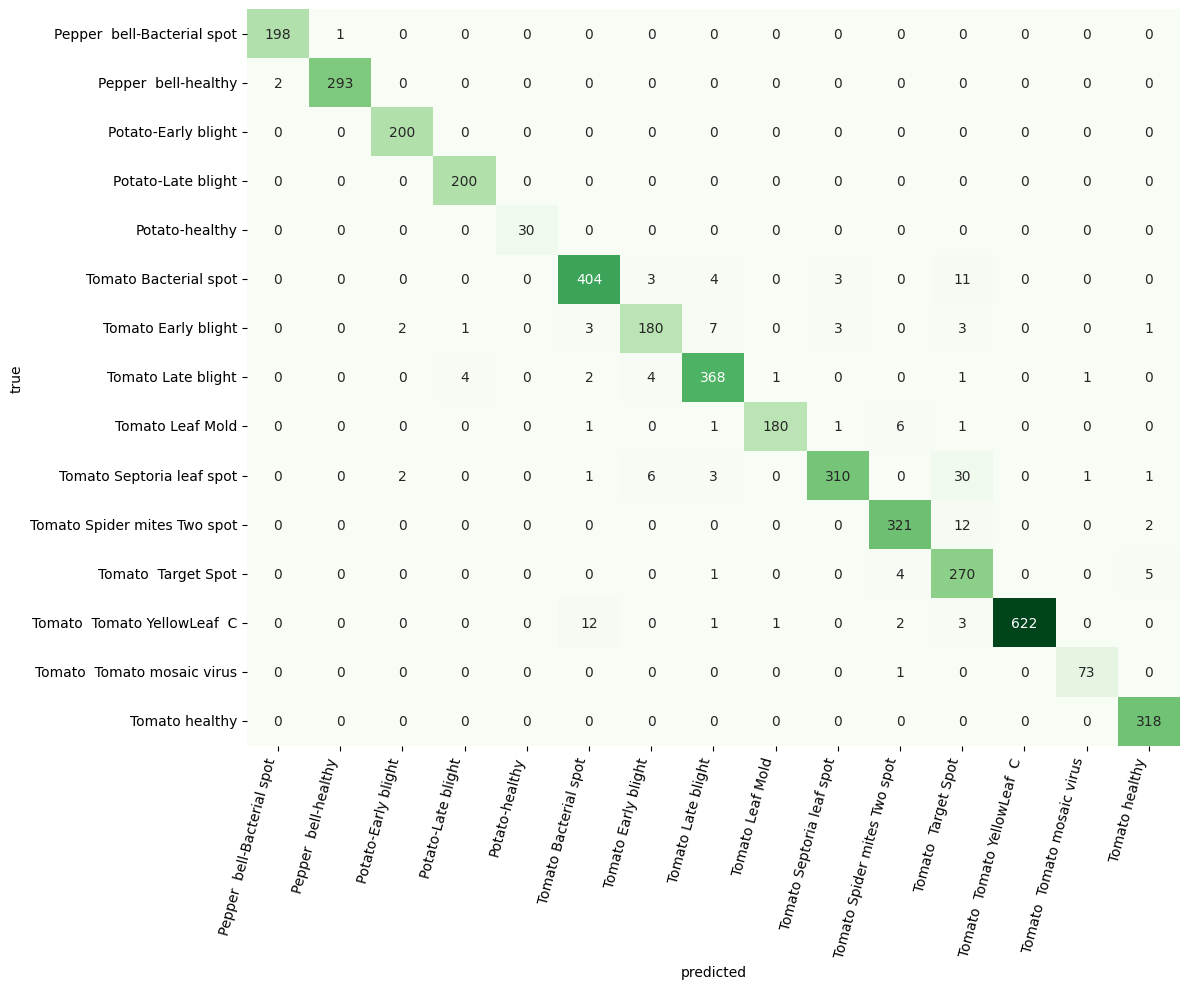

In [17]:
cm = np.array(metrics["confusion_matrix"])
short = [c.replace("___", "-").replace("_", " ")[:28] for c in class_names]
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=short, yticklabels=short, cbar=False)
plt.xlabel("predicted"); plt.ylabel("true"); plt.xticks(rotation=75, ha="right"); plt.tight_layout(); plt.show()

**Most confused pairs.** The biggest off-diagonal cells show which diseases the model mixes up. Expected output: a short table.

In [18]:
pairs = [(short[i], short[j], int(cm[i, j])) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j] > 0]
pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:8], columns=["true", "predicted as", "images"])

,true,predicted as,images
0,Tomato Septoria leaf spot,Tomato Target Spot,30
1,Tomato Spider mites Two spot,Tomato Target Spot,12
2,Tomato Tomato YellowLeaf C,Tomato Bacterial spot,12
3,Tomato Bacterial spot,Tomato Target Spot,11
4,Tomato Early blight,Tomato Late blight,7
5,Tomato Leaf Mold,Tomato Spider mites Two spot,6
6,Tomato Septoria leaf spot,Tomato Early blight,6
7,Tomato Target Spot,Tomato healthy,5


**Results summary.**
On the 4,122 test images the model reaches loss 0.162, accuracy 0.962, macro precision 0.965, macro recall 0.967 and macro F1 0.965. Validation accuracy at the end of training (about 0.96) matches the test accuracy, so there is no sign of overfitting.

The weakest class is **Tomato Target Spot** (precision 0.82, F1 0.88), mainly because other tomato spot diseases are predicted as Target Spot (Septoria 30 images, spider mites 12, bacterial spot 11). Tomato early blight has recall 0.90. All pepper and potato classes have F1 of 0.988 or higher. The remaining errors are between tomato diseases with similar small brown spots.

**Optimisation techniques used** *(for the report)*

| Technique | Where |
|---|---|
| Transfer learning (MobileNetV2, ImageNet) | `build_model` |
| Two-phase training: frozen head (lr 1e-3), then fine-tuning the top 80 layers (lr 1e-4) | training cells |
| Regularisation: Dropout 0.3 (x2) and L2 1e-4 | `build_model` |
| Data augmentation (flip, rotation, zoom, contrast) | `build_model` |
| Class weights for imbalance | `compute_class_weights` |
| Early stopping and learning-rate reduction | `default_callbacks` |
| Metrics: loss, accuracy, precision, recall, F1, confusion matrix | evaluation cells |

## 7. Save the model

**Save.** Writes `models/plant_disease_model.h5` and `models/class_names.json`, which the API uses. Expected output: file name and size.

In [19]:
save_model(model, class_names)
print(config.MODEL_PATH.name, round(config.MODEL_PATH.stat().st_size / 1e6, 1), "MB")
print(json.loads(config.CLASS_NAMES_PATH.read_text())[:3], "...")

plant_disease_model.h5 10.1 MB
['Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight'] ...


## 8. Prediction function

**Predict from a file.** `predict_leaf` loads the saved model through `src/prediction.py`, exactly like the API. Expected output: 4 random test leaves with true vs predicted class.

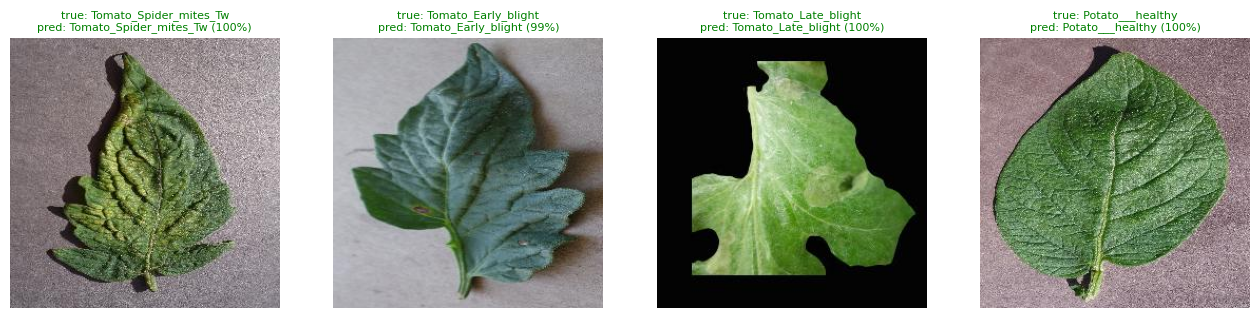

In [20]:
from src.prediction import predict_image

def predict_leaf(path, show=True):
    result = predict_image(path)
    if show:
        plt.imshow(Image.open(path)); plt.axis("off")
        plt.title(f"{result['label']} ({result['confidence']:.0%})", fontsize=9); plt.show()
    return result

samples = [random.choice(list((config.TEST_DIR / random.choice(class_names)).iterdir())) for _ in range(4)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, f in zip(axes, samples):
    r = predict_image(f)
    ax.imshow(Image.open(f)); ax.axis("off")
    ok = r["label"] == f.parent.name
    ax.set_title(f"true: {f.parent.name[:22]}\npred: {r['label'][:22]} ({r['confidence']:.0%})",
                 fontsize=8, color="green" if ok else "red")
plt.show()

## 9. Retraining

**Retraining entry point.** New images uploaded through the UI/API are saved in the database, preprocessed, and the saved model is fine-tuned. The cell is commented out so it does not run by accident. Expected output (if run): a message with old and new accuracy.

In [21]:
# from src.retrain import run_retraining
# run_retraining("notebook")
print("Retraining is triggered from the UI/API (button or automatic threshold) - see README.")

Retraining is triggered from the UI/API (button or automatic threshold) - see README.


**Download the model.** Colab deletes files when the session ends, so save the model to your computer. Expected output: two files downloaded.

In [22]:
from google.colab import files
files.download("models/plant_disease_model.h5")
files.download("models/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>